# SIS 1 – Economy of Kazakhstan: Income, Inflation, Unemployment and Human Development

**Course:** Data Collection & Preparation
**Author:** Ospanov Daniyar (individual project)

## Research question
How does the economy of Kazakhstan compare with Central Asia and neighbouring countries
(GDP per capita, inflation, unemployment), and how are these economic indicators related to the
**Human Development Index (HDI)** of a country?

## Data sources
| Source | Type | What we take |
|---|---|---|
| [World Bank Indicators API](https://api.worldbank.org/v2) | API (JSON) | GDP per capita (current US$), inflation (CPI, % per year), unemployment (% of labour force), 2010–2023 |
| Wikipedia pages *List of countries by Human Development Index* and *List of countries in Asia and Oceania by Human Development Index* | static web pages (HTML tables) | HDI value and world rank for each country |

## Pipeline
1. Collect economic data (API) → 2. Collect HDI table (scraping) → 3. Clean → 4. Merge → 5. EDA → 6. Visualize → 7. Conclusions

In [1]:
import re
import time
import unicodedata
import warnings
from functools import reduce
from pathlib import Path
from urllib.robotparser import RobotFileParser

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)

Path("figures").mkdir(exist_ok=True)
Path("data").mkdir(exist_ok=True)

START_YEAR = 2010
END_YEAR = 2023
AVG_FROM = 2015          # country-level averages use 2015-2023

## 1. Countries
The World Bank API identifies countries by ISO3 code. `group` marks Kazakhstan, the other Central Asian
countries, and neighbouring / comparison countries.

In [2]:
countries = pd.DataFrame(
    [
        # iso3, country, group
        ("KAZ", "Kazakhstan",  "Kazakhstan"),
        ("UZB", "Uzbekistan",  "Central Asia"),
        ("KGZ", "Kyrgyzstan",  "Central Asia"),
        ("TJK", "Tajikistan",  "Central Asia"),
        ("TKM", "Turkmenistan", "Central Asia"),
        ("RUS", "Russia",      "Neighbours & others"),
        ("CHN", "China",       "Neighbours & others"),
        ("TUR", "Turkiye",     "Neighbours & others"),
        ("AZE", "Azerbaijan",  "Neighbours & others"),
        ("GEO", "Georgia",     "Neighbours & others"),
        ("ARM", "Armenia",     "Neighbours & others"),
        ("BLR", "Belarus",     "Neighbours & others"),
        ("MNG", "Mongolia",    "Neighbours & others"),
        ("POL", "Poland",      "Neighbours & others"),
        ("DEU", "Germany",     "Neighbours & others"),
        ("KOR", "South Korea", "Neighbours & others"),
    ],
    columns=["iso3", "country", "group"],
)
countries

,iso3,country,group
0,KAZ,Kazakhstan,Kazakhstan
1,UZB,Uzbekistan,Central Asia
2,KGZ,Kyrgyzstan,Central Asia
3,TJK,Tajikistan,Central Asia
4,TKM,Turkmenistan,Central Asia
5,RUS,Russia,Neighbours & others
6,CHN,China,Neighbours & others
7,TUR,Turkiye,Neighbours & others
8,AZE,Azerbaijan,Neighbours & others
9,GEO,Georgia,Neighbours & others


## 2. Data source 1 – World Bank API
One request per indicator: the API accepts several countries at once (`KAZ;UZB;...`).
The answer is JSON: a list with two elements – metadata and the data rows.
The function retries when a request fails.

In [3]:
WB_URL = "https://api.worldbank.org/v2/country/{codes}/indicator/{indicator}"

INDICATORS = {
    "NY.GDP.PCAP.CD": "gdp_per_capita",   # GDP per capita, current US$
    "FP.CPI.TOTL.ZG": "inflation",        # inflation, consumer prices, % per year
    "SL.UEM.TOTL.ZS": "unemployment",     # unemployment, % of labour force (ILO estimate)
}


def get_indicator(indicator, column, retries=3):
    # Download one indicator for all countries and return a DataFrame.
    url = WB_URL.format(codes=";".join(countries["iso3"]), indicator=indicator)
    params = {"format": "json", "per_page": 2000, "date": f"{START_YEAR}:{END_YEAR}"}

    for attempt in range(1, retries + 1):
        try:
            response = requests.get(url, params=params, timeout=60)
            response.raise_for_status()
            payload = response.json()
            if len(payload) < 2 or payload[1] is None:
                raise ValueError(f"empty answer: {payload[0]}")
            rows = [
                {
                    "iso3": item["countryiso3code"],
                    "year": item["date"],
                    column: item["value"],
                }
                for item in payload[1]
            ]
            return pd.DataFrame(rows)
        except Exception as error:
            print(f"  {column}: attempt {attempt} failed ({error})")
            time.sleep(3 * attempt)
    return None


frames = []
for code_, column in INDICATORS.items():
    print("Downloading:", column)
    df_ind = get_indicator(code_, column)
    if df_ind is not None:
        frames.append(df_ind)
    time.sleep(1)  # be polite to the API

# put the three indicators side by side: one row = one country in one year
econ_raw = reduce(lambda left, right: left.merge(right, on=["iso3", "year"], how="outer"), frames)
econ_raw.to_csv("data/economy_raw.csv", index=False)
print("Raw economy shape:", econ_raw.shape)
econ_raw.head()

Downloading: gdp_per_capita
Downloading: inflation
Downloading: unemployment
Raw economy shape: (224, 5)


,iso3,year,gdp_per_capita,inflation,unemployment
0,ARM,2010,3041.344507,8.176361,19.523
1,ARM,2011,3349.553098,7.650008,18.884
2,ARM,2012,3511.563997,2.558020,17.511
3,ARM,2013,3680.166922,5.789668,16.576
4,ARM,2014,3852.118006,2.981309,17.498


## 3. Data source 2 – HDI tables scraped from Wikipedia
Two static Wikipedia pages are used: the main list of countries by HDI and the list for Asia and Oceania.
The main page does **not** contain every country in its HTML (for example Kazakhstan and Kyrgyzstan were missing when we checked),
so the Asia page is used to fill the gaps. The scraper

1. reads **robots.txt** and checks that each URL may be downloaded,
2. goes through all tables with class `wikitable`,
3. in every row takes the **HDI value** (first cell that looks like `0.xxx`), the **country name** (first text cell before it)
   and the **world rank** (the last whole number before the name),
4. keeps only the first appearance of each country (the main page comes first).

The page layout may change over time, so the notebook prints what was found and how many rows were read.

In [4]:
WIKI_URLS = [
    "https://en.wikipedia.org/wiki/List_of_countries_by_Human_Development_Index",
    # the main list is missing some countries in its HTML, this page fills the gaps (Central Asia etc.)
    "https://en.wikipedia.org/wiki/List_of_countries_in_Asia_and_Oceania_by_Human_Development_Index",
]
USER_AGENT = "SIS1-DataCollection-Student/1.0 (university coursework)"
HEADERS = {"User-Agent": USER_AGENT}

# --- respect robots.txt ---
robots = RobotFileParser()
robots.parse(requests.get("https://en.wikipedia.org/robots.txt", headers=HEADERS, timeout=30).text.splitlines())
for page_url in WIKI_URLS:
    print("Allowed to scrape:", robots.can_fetch(USER_AGENT, page_url), "-", page_url.split("/")[-1])


def clean_cell(text):
    text = re.sub(r"\[.*?\]", "", text)          # remove footnote marks like [a] or [12]
    return text.replace("\xa0", " ").strip()


def scrape_hdi(url):
    # Return a DataFrame with columns: country_wiki, hdi_rank, hdi.
    if not robots.can_fetch(USER_AGENT, url):
        print("  blocked by robots.txt:", url)
        return pd.DataFrame(columns=["country_wiki", "hdi_rank", "hdi"])

    response = requests.get(url, headers=HEADERS, timeout=30)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, "html.parser")

    rows, tables = [], soup.find_all("table", class_="wikitable")
    print(f"{url.split('/')[-1]}: tables with class wikitable = {len(tables)}")

    for table in tables:
        for tr in table.find_all("tr"):
            cells = [clean_cell(c.get_text(" ", strip=True)) for c in tr.find_all(["td", "th"])]

            # HDI value: first cell like 0.803
            hdi_idx = next((i for i, c in enumerate(cells) if re.fullmatch(r"0\.\d{3}", c)), None)
            if hdi_idx is None:
                continue

            # country name: first cell before the HDI value that contains letters
            name_idx = next((i for i, c in enumerate(cells[:hdi_idx]) if re.search(r"[A-Za-z]{3,}", c)), None)
            if name_idx is None:
                continue

            # world rank: the last whole number before the name (may be missing for some rows)
            ranks = [int(c) for c in cells[:name_idx] if re.fullmatch(r"\d{1,3}", c)]
            rows.append({
                "country_wiki": cells[name_idx],
                "hdi_rank": ranks[-1] if ranks else np.nan,
                "hdi": float(cells[hdi_idx]),
            })

    return pd.DataFrame(rows)


parts = []
for page_url in WIKI_URLS:
    part = scrape_hdi(page_url)
    print("  rows scraped:", len(part))
    parts.append(part)
    time.sleep(1)  # do not hammer the server

hdi_raw = pd.concat(parts, ignore_index=True)   # main page first, Asia page second
hdi_raw.to_csv("data/hdi_raw.csv", index=False)
print("Rows scraped in total:", len(hdi_raw))
print("Kazakhstan found:", hdi_raw["country_wiki"].str.contains("Kazakhstan").any())
hdi_raw.head(10)

Allowed to scrape: True - List_of_countries_by_Human_Development_Index
Allowed to scrape: True - List_of_countries_in_Asia_and_Oceania_by_Human_Development_Index
List_of_countries_by_Human_Development_Index: tables with class wikitable = 3
  rows scraped: 174
List_of_countries_in_Asia_and_Oceania_by_Human_Development_Index: tables with class wikitable = 1
  rows scraped: 64
Rows scraped in total: 238
Kazakhstan found: True


,country_wiki,hdi_rank,hdi
0,Iceland,1.0,0.972
1,Norway,2.0,0.970
2,Denmark,4.0,0.962
3,Germany,5.0,0.959
4,Australia,7.0,0.958
5,Hong Kong,8.0,0.955
6,Belgium,10.0,0.951
7,Ireland,11.0,0.949
8,Finland,12.0,0.948
9,Singapore,13.0,0.946


## 4. Data cleaning
Checks done for each dataset: types, missing values, duplicates, impossible values, column names.

In [5]:
print("=== ECONOMY: before cleaning ===")
econ_raw.info()
print("\nMissing values:\n", econ_raw.isna().sum())
print("Duplicated rows (iso3 + year):", econ_raw.duplicated(subset=["iso3", "year"]).sum())

=== ECONOMY: before cleaning ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 224 entries, 0 to 223
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   iso3            224 non-null    object 
 1   year            224 non-null    object 
 2   gdp_per_capita  224 non-null    float64
 3   inflation       209 non-null    float64
 4   unemployment    224 non-null    float64
dtypes: float64(3), object(2)
memory usage: 8.9+ KB

Missing values:
 iso3               0
year               0
gdp_per_capita     0
inflation         15
unemployment       0
dtype: int64
Duplicated rows (iso3 + year): 0


In [6]:
econ = econ_raw.copy()

# data types
econ["year"] = pd.to_numeric(econ["year"], errors="coerce").astype("Int64")
for col in ["gdp_per_capita", "inflation", "unemployment"]:
    econ[col] = pd.to_numeric(econ[col], errors="coerce")

# duplicates
before = len(econ)
econ = econ.drop_duplicates(subset=["iso3", "year"])
print("Duplicates removed:", before - len(econ))

# impossible values -> missing
econ.loc[econ["gdp_per_capita"] <= 0, "gdp_per_capita"] = np.nan
econ.loc[~econ["unemployment"].between(0, 100), "unemployment"] = np.nan
econ.loc[econ["inflation"] < -50, "inflation"] = np.nan

# add the readable country name and group
econ = econ.merge(countries, on="iso3", how="left")
econ = econ.sort_values(["country", "year"]).reset_index(drop=True)

# how many values are missing for each country?
print("\nMissing values per country (2010-2023 = 14 years per indicator):")
missing = econ.groupby("country")[["gdp_per_capita", "inflation", "unemployment"]].apply(lambda d: d.isna().sum())
print(missing.sort_values("gdp_per_capita", ascending=False).head(8))

# short gaps (up to 2 years) are interpolated inside each country; long gaps stay missing
cols = ["gdp_per_capita", "inflation", "unemployment"]
econ[cols] = econ.groupby("country")[cols].transform(lambda s: s.interpolate(limit=2, limit_area="inside"))
print("\nMissing values left after interpolation:\n", econ[cols].isna().sum())

econ.describe().round(2)

Duplicates removed: 0

Missing values per country (2010-2023 = 14 years per indicator):
            gdp_per_capita  inflation  unemployment
country                                            
Armenia                  0          0             0
Azerbaijan               0          0             0
Belarus                  0          0             0
China                    0          0             0
Georgia                  0          0             0
Germany                  0          0             0
Kazakhstan               0          0             0
Kyrgyzstan               0          0             0

Missing values left after interpolation:
 gdp_per_capita     0
inflation         15
unemployment       0
dtype: int64


,year,gdp_per_capita,inflation,unemployment
count,224.0,224.00,209.00,224.00
mean,2016.5,10818.97,7.25,6.82
std,4.04,12015.58,8.71,4.19
min,2010.0,737.34,-1.40,2.68
25%,2013.0,3864.82,2.49,4.28
50%,2016.5,6664.75,5.87,5.17
75%,2020.0,12425.70,8.79,7.04
max,2023.0,54776.77,72.31,20.20


In [7]:
print("=== HDI: before cleaning ===")
print(hdi_raw.dtypes)
print("Duplicated countries:", hdi_raw["country_wiki"].duplicated().sum())


def norm(name):
    # Make country names comparable: no accents, lower case, no brackets, known aliases unified.
    name = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode().lower()
    name = re.sub(r"\(.*?\)", "", name)
    name = re.sub(r"^the ", "", name).strip()
    aliases = {
        "turkey": "turkiye",
        "russian federation": "russia",
        "kyrgyz republic": "kyrgyzstan",
        "korea, south": "south korea",
        "republic of korea": "south korea",
        "georgia (country)": "georgia",
    }
    return aliases.get(name, name)


hdi = hdi_raw.copy()
hdi["key"] = hdi["country_wiki"].map(norm)

# the same country appears in several tables/pages -> keep the first row (the main page comes first)
hdi = hdi.drop_duplicates(subset="key", keep="first").reset_index(drop=True)
hdi = hdi.dropna(subset=["hdi"])
hdi = hdi[hdi["hdi"].between(0, 1)]
hdi["hdi_rank"] = hdi["hdi_rank"].astype("Int64")
print("Countries after cleaning:", len(hdi))
hdi.head()

=== HDI: before cleaning ===
country_wiki     object
hdi_rank        float64
hdi             float64
dtype: object
Duplicated countries: 47
Countries after cleaning: 191


,country_wiki,hdi_rank,hdi,key
0,Iceland,1,0.972,iceland
1,Norway,2,0.970,norway
2,Denmark,4,0.962,denmark
3,Germany,5,0.959,germany
4,Australia,7,0.958,australia


## 5. Merging
1. The yearly data are aggregated to **one row per country** (mean of 2015–2023).
   A country needs at least 5 years of data for an indicator, otherwise the average is left empty.
2. The result is merged with the HDI table by the normalised country name (`key`), inner join, one-to-one.

In [8]:
recent = econ[econ["year"] >= AVG_FROM]


def mean_if_enough(s, min_years=5):
    return s.mean() if s.notna().sum() >= min_years else np.nan


country_level = (
    recent.groupby(["country", "group"])[["gdp_per_capita", "inflation", "unemployment"]]
    .agg(mean_if_enough)
    .reset_index()
)
country_level["key"] = country_level["country"].map(norm)

merged = country_level.merge(hdi[["key", "hdi", "hdi_rank"]], on="key", how="inner", validate="one_to_one")
merged["log_gdp"] = np.log10(merged["gdp_per_capita"])
merged = merged.drop(columns="key").round(3)

print("Countries without HDI match:", sorted(set(country_level["country"]) - set(merged["country"])) or "none")
print("Countries with missing economic values:",
      merged.loc[merged[["gdp_per_capita", "inflation", "unemployment"]].isna().any(axis=1), "country"].tolist() or "none")

merged.to_csv("data/merged_country_data.csv", index=False)
merged.sort_values("hdi", ascending=False)

Countries without HDI match: none
Countries with missing economic values: ['Turkmenistan']


,country,group,gdp_per_capita,inflation,unemployment,hdi,hdi_rank,log_gdp
5,Germany,Neighbours & others,48003.600,2.414,3.636,0.959,5,4.681
11,South Korea,Neighbours & others,33905.830,1.912,3.502,0.937,20,4.530
9,Poland,Neighbours & others,16263.392,4.329,4.174,0.906,35,4.211
13,Turkiye,Neighbours & others,10548.619,24.016,11.309,0.853,51,4.023
4,Georgia,Neighbours & others,5176.899,5.422,13.108,0.844,57,3.714
6,Kazakhstan,Kazakhstan,9827.140,9.362,4.955,0.837,60,3.992
10,Russia,Neighbours & others,11489.484,7.033,4.793,0.832,64,4.060
2,Belarus,Neighbours & others,6657.129,8.566,4.587,0.824,65,3.823
0,Armenia,Neighbours & others,4820.448,2.920,16.706,0.811,69,3.683
3,China,Neighbours & others,10586.125,1.735,4.639,0.797,78,4.025


## 6. Exploratory data analysis
Descriptive statistics and correlations with HDI. With a small number of countries the results are only indicative,
so **Pearson** (linear) and **Spearman** (rank) coefficients are reported together with p-values.
GDP per capita is analysed on a log scale because it is strongly skewed.

In [9]:
merged.describe().round(2)

,gdp_per_capita,inflation,unemployment,hdi,hdi_rank,log_gdp
count,16.00,15.00,16.00,16.00,16.0,16.00
mean,11029.05,7.10,6.53,0.82,71.0,3.83
std,12640.44,5.51,3.81,0.08,34.19,0.45
min,915.79,1.74,3.50,0.69,5.0,2.96
25%,4626.31,3.62,4.48,0.76,55.5,3.67
50%,5973.87,6.49,4.87,0.82,67.0,3.77
75%,10811.96,7.97,6.65,0.85,97.25,4.03
max,48003.60,24.02,16.71,0.96,128.0,4.68


In [10]:
print("Mean values by group:")
merged.groupby("group")[["gdp_per_capita", "inflation", "unemployment", "hdi"]].mean().round(2)

Mean values by group:


,gdp_per_capita,inflation,unemployment,hdi
group,,,,
Central Asia,2393.03,8.22,5.27,0.73
Kazakhstan,9827.14,9.36,4.96,0.84
Neighbours & others,14278.69,6.60,7.13,0.85


In [11]:
analysis = merged.dropna(subset=["log_gdp", "inflation", "unemployment", "hdi"])
print("Countries used for correlations:", len(analysis))

rows = []
for var in ["log_gdp", "inflation", "unemployment"]:
    pearson_r, pearson_p = stats.pearsonr(analysis[var], analysis["hdi"])
    spearman_r, spearman_p = stats.spearmanr(analysis[var], analysis["hdi"])
    rows.append({"variable": var, "pearson_r": pearson_r, "pearson_p": pearson_p,
                 "spearman_rho": spearman_r, "spearman_p": spearman_p})

corr_table = pd.DataFrame(rows).round(3)
corr_table

Countries used for correlations: 15


,variable,pearson_r,pearson_p,spearman_rho,spearman_p
0,log_gdp,0.947,0.000,0.871,0.000
1,inflation,-0.166,0.554,-0.254,0.362
2,unemployment,-0.118,0.675,-0.400,0.140


## 7. Visualizations
Four labelled plots (saved to the `figures/` folder).

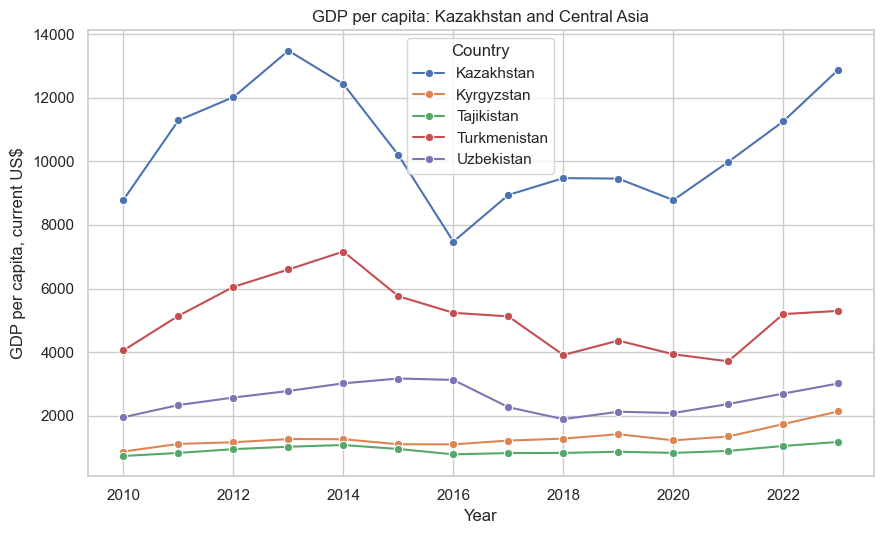

In [12]:
# Plot 1: GDP per capita over time, Kazakhstan and Central Asia
plot_df = econ[econ["group"].isin(["Kazakhstan", "Central Asia"])]
plt.figure(figsize=(9, 5.5))
sns.lineplot(data=plot_df, x="year", y="gdp_per_capita", hue="country", marker="o")
plt.title("GDP per capita: Kazakhstan and Central Asia")
plt.xlabel("Year")
plt.ylabel("GDP per capita, current US$")
plt.legend(title="Country")
plt.tight_layout()
plt.savefig("figures/fig1_gdp_per_capita_central_asia.png", dpi=200)
plt.show()

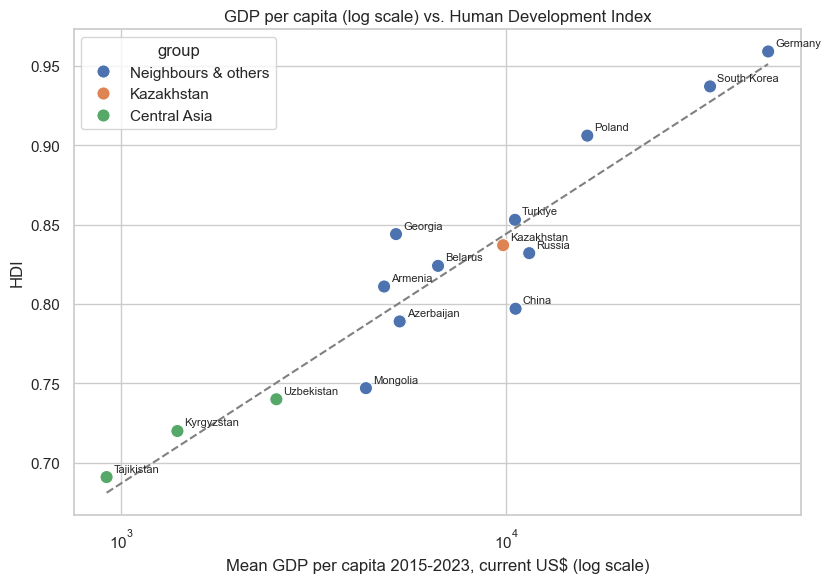

In [13]:
# Plot 2: income vs. human development
plt.figure(figsize=(8.5, 6))
sns.scatterplot(data=analysis, x="gdp_per_capita", y="hdi", hue="group", s=90)
# trend line: straight line fitted on log10(GDP), drawn on the log axis
x_line = np.linspace(analysis["log_gdp"].min(), analysis["log_gdp"].max(), 50)
slope, intercept = np.polyfit(analysis["log_gdp"], analysis["hdi"], 1)
plt.plot(10 ** x_line, intercept + slope * x_line, color="grey", linestyle="--")
plt.xscale("log")
for r in analysis.itertuples():
    plt.annotate(r.country, (r.gdp_per_capita, r.hdi), textcoords="offset points", xytext=(5, 4), fontsize=8)
plt.title("GDP per capita (log scale) vs. Human Development Index")
plt.xlabel("Mean GDP per capita 2015-2023, current US$ (log scale)")
plt.ylabel("HDI")
plt.tight_layout()
plt.savefig("figures/fig2_gdp_vs_hdi.png", dpi=200)
plt.show()

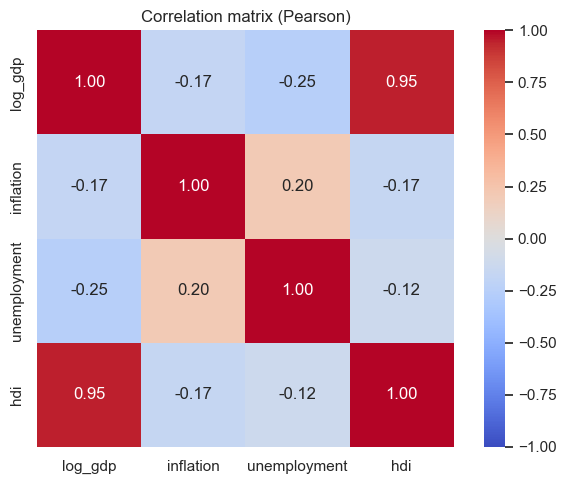

In [14]:
# Plot 3: correlation heatmap
plt.figure(figsize=(6.5, 5))
corr = analysis[["log_gdp", "inflation", "unemployment", "hdi"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix (Pearson)")
plt.tight_layout()
plt.savefig("figures/fig3_correlation_heatmap.png", dpi=200)
plt.show()

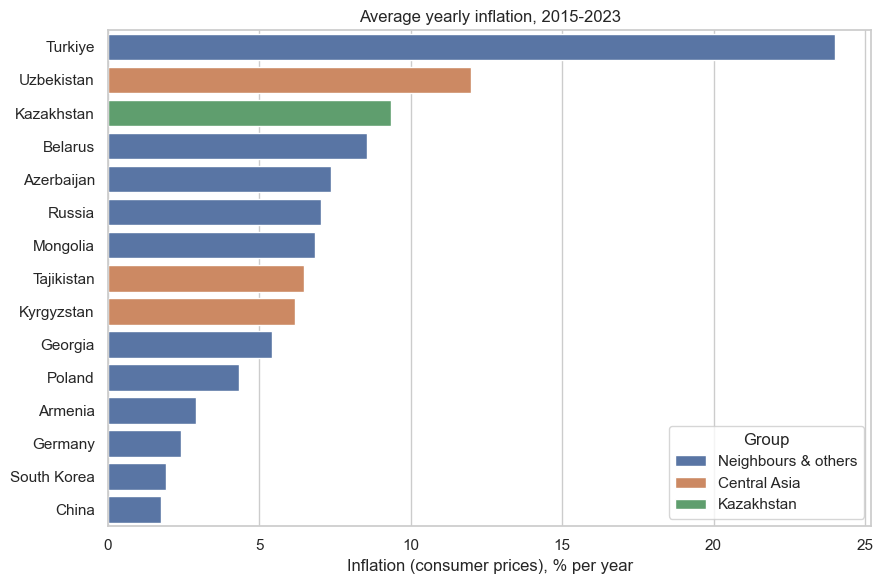

In [15]:
# Plot 4: average inflation by country
order = merged.dropna(subset=["inflation"]).sort_values("inflation", ascending=False)
plt.figure(figsize=(9, 6))
sns.barplot(data=order, y="country", x="inflation", hue="group", dodge=False)
plt.title("Average yearly inflation, 2015-2023")
plt.xlabel("Inflation (consumer prices), % per year")
plt.ylabel("")
plt.legend(title="Group")
plt.tight_layout()
plt.savefig("figures/fig4_inflation_by_country.png", dpi=200)
plt.show()

## 8. Key numbers and conclusions
The next cell prints the main results so they can be used in the written report.

In [16]:
print(f"Countries in the final table: {len(merged)}")
print(f"Period: {START_YEAR}-{END_YEAR} (averages {AVG_FROM}-{END_YEAR})")
print()

kaz = merged[merged["country"] == "Kazakhstan"]
if not kaz.empty:
    k = kaz.iloc[0]
    rank_gdp = int((merged["gdp_per_capita"] > k["gdp_per_capita"]).sum() + 1)
    rank_hdi = int((merged["hdi"] > k["hdi"]).sum() + 1)
    print("Kazakhstan:")
    print(f"  GDP per capita: {k['gdp_per_capita']:.0f} US$ (place {rank_gdp} of {len(merged)} in our table)")
    print(f"  Inflation: {k['inflation']:.1f} %   Unemployment: {k['unemployment']:.1f} %")
    print(f"  HDI: {k['hdi']} (place {rank_hdi} of {len(merged)} in our table)")
print()
print("Correlations with HDI:")
print(corr_table.to_string(index=False))
print()
print("Mean values by group:")
print(merged.groupby("group")[["gdp_per_capita", "inflation", "unemployment", "hdi"]].mean().round(2).to_string())

Countries in the final table: 16
Period: 2010-2023 (averages 2015-2023)

Kazakhstan:
  GDP per capita: 9827 US$ (place 7 of 16 in our table)
  Inflation: 9.4 %   Unemployment: 5.0 %
  HDI: 0.837 (place 6 of 16 in our table)

Correlations with HDI:
    variable  pearson_r  pearson_p  spearman_rho  spearman_p
     log_gdp      0.947      0.000         0.871       0.000
   inflation     -0.166      0.554        -0.254       0.362
unemployment     -0.118      0.675        -0.400       0.140

Mean values by group:
                     gdp_per_capita  inflation  unemployment   hdi
group                                                             
Central Asia                2393.03       8.22          5.27  0.73
Kazakhstan                  9827.14       9.36          4.96  0.84
Neighbours & others        14278.69       6.60          7.13  0.85


### Conclusions (fill in after running the notebook, in your own words)
* **Kazakhstan vs. Central Asia:** is income per person higher or lower, and what about inflation and unemployment?
* **Economy and human development:** which indicator is related to HDI (see the correlation table and plot 2)? Is the relation positive or negative, strong or weak?
* **Limitations:**
  * only about 15 countries, so correlations are indicative, not proof;
  * country averages hide changes over time (for example the 2022 inflation jump in the region);
  * HDI is published once per year and comes from Wikipedia, which copies the UNDP report;
  * some indicators are missing for some countries (for example Turkmenistan), so those countries are excluded from the correlations;
  * GDP per capita in current US$ is affected by exchange rate changes (for example the tenge devaluations).
* **Ideas for improvement:** add more countries and more indicators (oil prices, exports, education), use panel data over time.